<h2><center>MNIST classification</center></h2>

In [67]:
# As a first step, we may want to switch to a GPU-acceperated VM
# In the menu: Runtime->Change runtime type->Hardware Accelerator->GPU.
#
# This will thest if we have a GPU-equipped VM and return some useful system-level information
!nvidia-smi

# Which GNU/Linux distribution is installed on our VM ?
!lsb_release -a

# Which version of the Linux kernel our VM has ?
!uname -a

# How much free memory our VM has ?
!free -h

# Which storage facilities our VM has ?
!mount

# Which python version our VM has installed ?
!python --version

Mon Nov 16 15:05:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   69C    P0             29W /   70W |     163MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Importing Torch and related libraries

In [68]:
# Importing Torch 2.x module
import torch, torchvision
print("Using Torch version " + str(torch.__version__))

Using Torch version 2.14.1+cu130


In [69]:
# Torchvision provides datasets and more for CV tasks
import torchvision
print("Using Torch version " + str(torchvision.__version__))

Using Torch version 0.29.1+cu130


In [70]:
# Thid is optional for experiment reproducibility
#torch.manual_seed(1)

# Loading and preparing the MNIST dataset

In [71]:
#These transforms actually perform scaling only
from torchvision.transforms import v2

# Defining the tranformations we want to apply to our dataset (0-1 normalization in this case)
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

In [72]:
# Loading into memory the datasets for training and testing applying scaling
from torchvision import datasets

training_set = datasets.MNIST('./data', train=True, transform=transform, download=True)
test_set = datasets.MNIST('./data', train=False, transform=transform, download=True)

Creating a dataloder for the train and test datasets

In [73]:
from torch.utils.data import DataLoader

# Batch sizes are usually multiples of 2 in the 16-32 range
batch_size = 32

# Creating one data loader for the training set and one for the test set
train_dataloader = DataLoader(training_set, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

# Inspecting the train images and labels...
for X, y in train_dataloader:
    print(f"Shape of train images [N, C, H, W]: {X.shape}")
    print(f"Shape of train labels: {y.shape} {y.dtype}")
    break

# ... and the test images and labels
for X, y in test_dataloader:
    print(f"Shape of train images [N, C, H, W]: {X.shape}")
    print(f"Shape of train labels: {y.shape} {y.dtype}")
    break

Shape of train images [N, C, H, W]: torch.Size([32, 1, 28, 28])
Shape of train labels: torch.Size([32]) torch.int64
Shape of train images [N, C, H, W]: torch.Size([32, 1, 28, 28])
Shape of train labels: torch.Size([32]) torch.int64


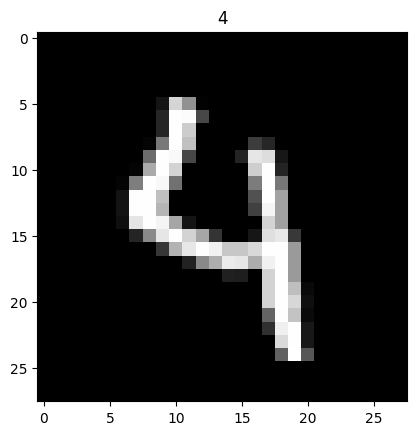

In [74]:
# Let us visualize the first training sample in the batch using the Gnuplot library
from matplotlib import pyplot as plt

for X, y in train_dataloader:
    plt.imshow(X[0, 0], cmap='grey')
    plt.title(y[0].item())
    break

# Defining the Model

In [75]:
from torch import nn

# Define a LeNet300-like model
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.model = nn.Sequential(
            nn.Linear(28*28, 300),
            nn.ReLU(),
            nn.Linear(300, 100),
            nn.ReLU(),
            nn.Linear(100, 10),
            nn.LogSoftmax(1)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.model(x)
        return logits

# This is the model instance that will be trained and tested
model = MyModel()

In [76]:
# Getting hold of our GPU
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

# The model is bound to the GPU
model = model.to(device)
print(model)

Using cuda device
MyModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (model): Sequential(
    (0): Linear(in_features=784, out_features=300, bias=True)
    (1): ReLU()
    (2): Linear(in_features=300, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
    (5): LogSoftmax(dim=1)
  )
)


# Instantiate one loss function and an optimizer

In [77]:
#Since we have a LogSoftMax layer in our model, we use NLLLoss instead of CrossEntropyLoss
loss_fn = nn.NLLLoss()
# The optimizers module provides a number of optimization algorithms for updating
# a netwok parameters accoridng to the computed error gradints
optimizer = torch.optim.SGD(model.parameters(), lr=1e-1)

# Defnining the training function

In [78]:
# This is where the actual training-testing happens
def train_epoch(dataloader, model, loss_fn, optimizer, verbose = False):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if verbose and batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

# Defining the testing function

In [79]:
def eval_epoch(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            preds = model(X)
            test_loss += loss_fn(preds, y).item()
            correct += (preds.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    return test_loss, correct*100
    #print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

#Main training loop - here is where learning happens

In [65]:
#For being able to plot the training history afterwards
history = {}
history['train_loss'] = []
history['train_acc'] = []
history['test_loss'] = []
history['test_acc'] = []

epochs = 20
for e in range(epochs):
    # Updating the model parameters for one epoch
    train_epoch(train_dataloader, model, loss_fn, optimizer)
    # Testing on the train and testing sets to evaluate the model generalization ability
    train_loss, train_acc = eval_epoch(train_dataloader, model, loss_fn)
    test_loss, test_acc = eval_epoch(test_dataloader, model, loss_fn)

    print ('Epoch %d / %d lossTrain %.3f lossTest %.3f accuracyTrain %.3f accuracyTest %.3f' %(int(e)+1, epochs, train_loss, test_loss, train_acc, test_acc))
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_acc)

print("Done!")

Epoch 1 / 20 lossTrain 0.450 lossTest 0.435 accuracyTrain 86.935 accuracyTest 87.490
Epoch 2 / 20 lossTrain 0.332 lossTest 0.322 accuracyTrain 90.347 accuracyTest 90.570
Epoch 3 / 20 lossTrain 0.283 lossTest 0.277 accuracyTrain 91.780 accuracyTest 91.770
Epoch 4 / 20 lossTrain 0.247 lossTest 0.243 accuracyTrain 92.895 accuracyTest 92.920
Epoch 5 / 20 lossTrain 0.217 lossTest 0.215 accuracyTrain 93.733 accuracyTest 93.770
Epoch 6 / 20 lossTrain 0.193 lossTest 0.193 accuracyTrain 94.425 accuracyTest 94.290
Epoch 7 / 20 lossTrain 0.173 lossTest 0.175 accuracyTrain 94.983 accuracyTest 94.790
Epoch 8 / 20 lossTrain 0.157 lossTest 0.160 accuracyTrain 95.475 accuracyTest 95.290
Epoch 9 / 20 lossTrain 0.143 lossTest 0.148 accuracyTrain 95.918 accuracyTest 95.510
Epoch 10 / 20 lossTrain 0.130 lossTest 0.137 accuracyTrain 96.278 accuracyTest 95.830
Epoch 11 / 20 lossTrain 0.120 lossTest 0.129 accuracyTrain 96.582 accuracyTest 96.180
Epoch 12 / 20 lossTrain 0.110 lossTest 0.121 accuracyTrain 96.8

# Visualizing the network performance

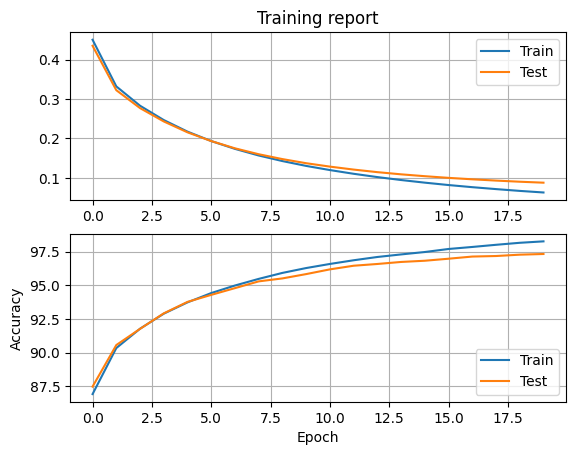

In [66]:
# We plot now the train and test loss and accuracy curves from history.history.keys()
_, axes = plt.subplots(nrows=2, ncols=1)

# Plotting the loss graph
axes[0].set_title("Training report")
axes[0].grid()
axes[0].plot(history['train_loss'])
axes[0].plot(history['test_loss'])
axes[0].set_ylabel=('Loss [bit]')
axes[0].legend(['Train', 'Test'], loc='upper right')

# Plotting the accuracy graph
axes[1].grid()
axes[1].plot(history['train_acc'])
axes[1].plot(history['test_acc'])
axes[1].set_ylabel('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend(['Train', 'Test'], loc='lower right')